# C-EX — What explains a weak cadmium-associated reporter response?

**Inputs.** Frozen expanded F-01 imaging findings, C-06 reference-sequence findings and the dated experimental-context review.
**Motivation.** A weak signal can reflect reporter abundance, reporter state, background, optics or assay variability.
**Goal.** Put the available evidence beside these alternatives and identify the measurement that distinguishes them.
**Prediction.** Imaging can describe reporter signal and technical behavior; it does not directly measure protein abundance.
This notebook completes an evidence review. It does not rerun image analysis or diagnose an expression defect.

In [1]:
from pathlib import Path
import hashlib, json, platform
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/input').is_dir() and (p / 'tasks').is_dir())
INPUT = ROOT / 'data/input'
OUTPUT = ROOT / 'data/output/C-EX'
OUTPUT.mkdir(parents=True, exist_ok=True)
F01_FILE = INPUT / 'F01_expanded_summary.json'  # Frozen results; no upstream task is run.
C06_FILE = INPUT / 'CEX_C06_summary.json'       # Supplied reference, not tested-clone identity.
CONTEXT_FILE = INPUT / 'F01_context_review.json'
INPUT_FILES = [F01_FILE, C06_FILE, CONTEXT_FILE]
STYLE = {'font.size': 9, 'font.family': 'DejaVu Sans',
         'svg.fonttype': 'none', 'savefig.dpi': 300}
# Keep the complete evidence sentences visible in notebook tables and their PDF export.
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)

## Materials and methods

Read the three frozen JSON inputs and retain their hashes. Copy each upstream result sentence verbatim into a source-findings table, with a source identifier. Extract the dated context claims separately. Build a transparent evidence-coverage matrix: measured imaging, reference sequence, preparation context or unresolved measurement. These are categories, not probabilities or effect scores.

**Scope and working assumptions.** The F-01 summary retains its own acquisition, nominal-condition and timing assumptions. C-06 describes the supplied reference only. Prior notebook observations remain prior observations. Frames, cells, fields and colony labels are not independent cultures. Fluorescence depends on reporter state and acquisition as well as abundance; it is not a direct protein-expression or cadmium-binding measurement. No significance tests or causal probabilities are calculated.

In [2]:
# Load actual saved findings rather than repeating numbers from memory.
f01, c06, context = [json.loads(p.read_text(encoding='utf-8')) for p in INPUT_FILES]
for source in [f01, c06]:
    if not isinstance(source.get('results'), list) or not source['results']:
        raise ValueError('Each frozen task summary must contain a non-empty results list.')
source_rows = [{'Evidence ID': f'{task}-{i:02d}', 'Source task': task, 'Finding': text}
               for task, summary in [('F-01', f01), ('C-06', c06)]
               for i, text in enumerate(summary['results'], 1)]
findings = pd.DataFrame(source_rows)
findings.to_csv(OUTPUT / 'source_findings.csv', index=False)
claims = pd.DataFrame(context['claims'])
claims[['id', 'source', 'locator', 'evidence_type', 'claim']].to_csv(
    OUTPUT / 'context_evidence.csv', index=False)
# Exact result sentences remain available in the matrix and source CSV.
f01_evidence = '\n'.join(f01['results'])
c06_evidence = '\n'.join(c06['results'])
matrix = pd.DataFrame([
    ['Recorded reporter behavior', 'Measured imaging', f01_evidence, 'F-01 results',
     'Use the acquisition-specific findings; do not infer a universal response.'],
    ['Optical artifacts / background', 'Measured imaging', f01_evidence, 'F-01 results and QC',
     'Consult the native-depth, background, clipping, focus and movement checks for each recording.'],
    ['Reference codon composition', 'Reference sequence', c06_evidence, 'C-06 results',
     'Codon descriptors locate reference features; they are not measured protein expression.'],
    ['Low protein expression is the cause', 'Unresolved',
     'No matched direct protein-abundance measurement is supplied.', 'Missing expression assay',
     'Measure reporter abundance in the same confirmed clones, conditions and cultures.'],
    ['Growth / viability / toxicity', 'Preparation context',
     'The 13-Oct preparation documents OD normalization; viability and same-time biomass are not measured.',
     'Context CTX02-CTX03', 'Obtain same-sample growth and viability data to test this explanation.'],
    ['Insufficient biological power', 'Unresolved',
     'Repeated cells, frames and fields do not establish independent-culture variability.',
     'F-01 hierarchy; missing culture IDs', 'Identify independent cultures and obtain culture-level response variation.'],
    ['Direct Cd binding or another site', 'Unresolved',
     'Imaging does not determine metal-binding sites or binding affinity.', 'Separate mechanistic question',
     'Use a confirmed protein sequence/model and an explicitly defined binding question.']
], columns=['Question / explanation', 'Evidence category', 'Evidence', 'Evidence source', 'Interpretation / next measurement'])
matrix['Input data'] = [F01_FILE.name, F01_FILE.name, C06_FILE.name,
                        'No direct expression data', CONTEXT_FILE.name, F01_FILE.name, 'No binding data']
matrix['Finished without more wet-lab data?'] = 'Yes: evidence review; no: causal diagnosis'
matrix.to_csv(OUTPUT / 'evidence_matrix.csv', index=False)

## Evidence classification

“Measured imaging” means the numerical results and QC are available in F-01, not that every recording passes every check. “Reference sequence” and “Preparation context” identify the type of information supplied. “Unresolved” identifies a missing measurement needed to assess that explanation. Read the exact source findings below the matrix; the classification does not convert fluorescence into an expression or binding assay.

In [3]:
# A categorical table makes evidence coverage visible without numerical scoring.
palette = {'Measured imaging': '#D8E9F4', 'Reference sequence': '#EEE1F2',
           'Preparation context': '#F7E7C5', 'Unresolved': '#E5E5E5'}
with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(9.4, 4.4))
    ax.axis('off')
    view = matrix[['Question / explanation', 'Evidence category']]
    table = ax.table(cellText=view.values, colLabels=view.columns, cellLoc='left',
                     colWidths=[0.63, 0.37], loc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.9)
    for (row, col), entry in table.get_celld().items():
        entry.set_edgecolor('#FFFFFF')
        entry.set_facecolor('#243746' if row == 0 else palette[view.iloc[row-1, 1]])
        if row == 0:
            entry.set_text_props(color='white', weight='bold')
    ax.set_title('Available evidence for the competing explanations', loc='left', pad=10)
    fig.text(0.02, 0.03, 'Categories describe evidence type, not probability, effect size or independent biological n.', fontsize=8)
    fig.tight_layout(rect=[0, 0.07, 1, 1])
    for extension in ['png', 'svg']:
        fig.savefig(OUTPUT / f'evidence_matrix.{extension}', bbox_inches='tight', dpi=300)
conclusion = ('The available imaging and reference analyses support a structured assessment of reporter behavior, '
              'technical conditions and reference codon composition. Low protein expression has not been identified '
              'as the cause of a weak response. Matched protein abundance, independent-culture identities and '
              'same-sample growth/viability measurements distinguish the remaining explanations.')
summary = {
    'title': 'C-EX: evidence for a weak cadmium-associated reporter response',
    'question': 'Which explanations are assessed by the supplied data, and which need a different measurement?',
    'materials': [p.name + ': frozen task summary or dated source-context review.' for p in INPUT_FILES],
    'methods': ['Preserve source result sentences verbatim; classify evidence type without scores or statistical tests.',
                'Compare the measured scope with the measurement each causal explanation requires.'],
    'scope_and_assumptions': 'F-01 acquisition and nominal-condition assumptions are inherited; C-06 is reference-only. '
        'This is a completed evidence review, not a causal expression, toxicity or direct-binding diagnosis.',
    'results': [f"The review retains {len(f01['results'])} F-01 findings and {len(c06['results'])} C-06 findings verbatim in source_findings.csv.",
                'Recorded imaging findings from F-01: ' + f01['conclusion']] +
               ['Selected reference-only finding from C-06:'] + c06['results'][:1] +
               ['Seven questions are classified by evidence type; direct expression, biological power and direct binding remain unresolved.'],
    'conclusion': conclusion,
    'table': {'columns': ['Question', 'Evidence type', 'Input data', 'Finished without more wet-lab data?'],
              'rows': matrix[['Question / explanation', 'Evidence category', 'Input data', 'Finished without more wet-lab data?']].values.tolist()},
    'figures': [{'file': 'evidence_matrix.png', 'caption': 'Categorical evidence coverage for seven questions. Colors encode source type only; no probability or statistical effect is implied.'}],
    'references': ['F-01 and C-06 frozen summaries: primary methods and references are preserved in those input JSON files.',
                   '13 October notebook context: CTX02-CTX06; original source hashes and locators in F01_context_review.json.']}
(OUTPUT / 'summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
provenance = {'inputs': {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in INPUT_FILES},
              'python': platform.python_version(), 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__,
              'method': 'Qualitative evidence synthesis; upstream source sentences retained unchanged',
              'independent_culture_n': None, 'statistical_tests': None, 'causal_probabilities': None}
(OUTPUT / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
plt.close(fig)  # Display the saved, identical figure in the results cell.

## Results

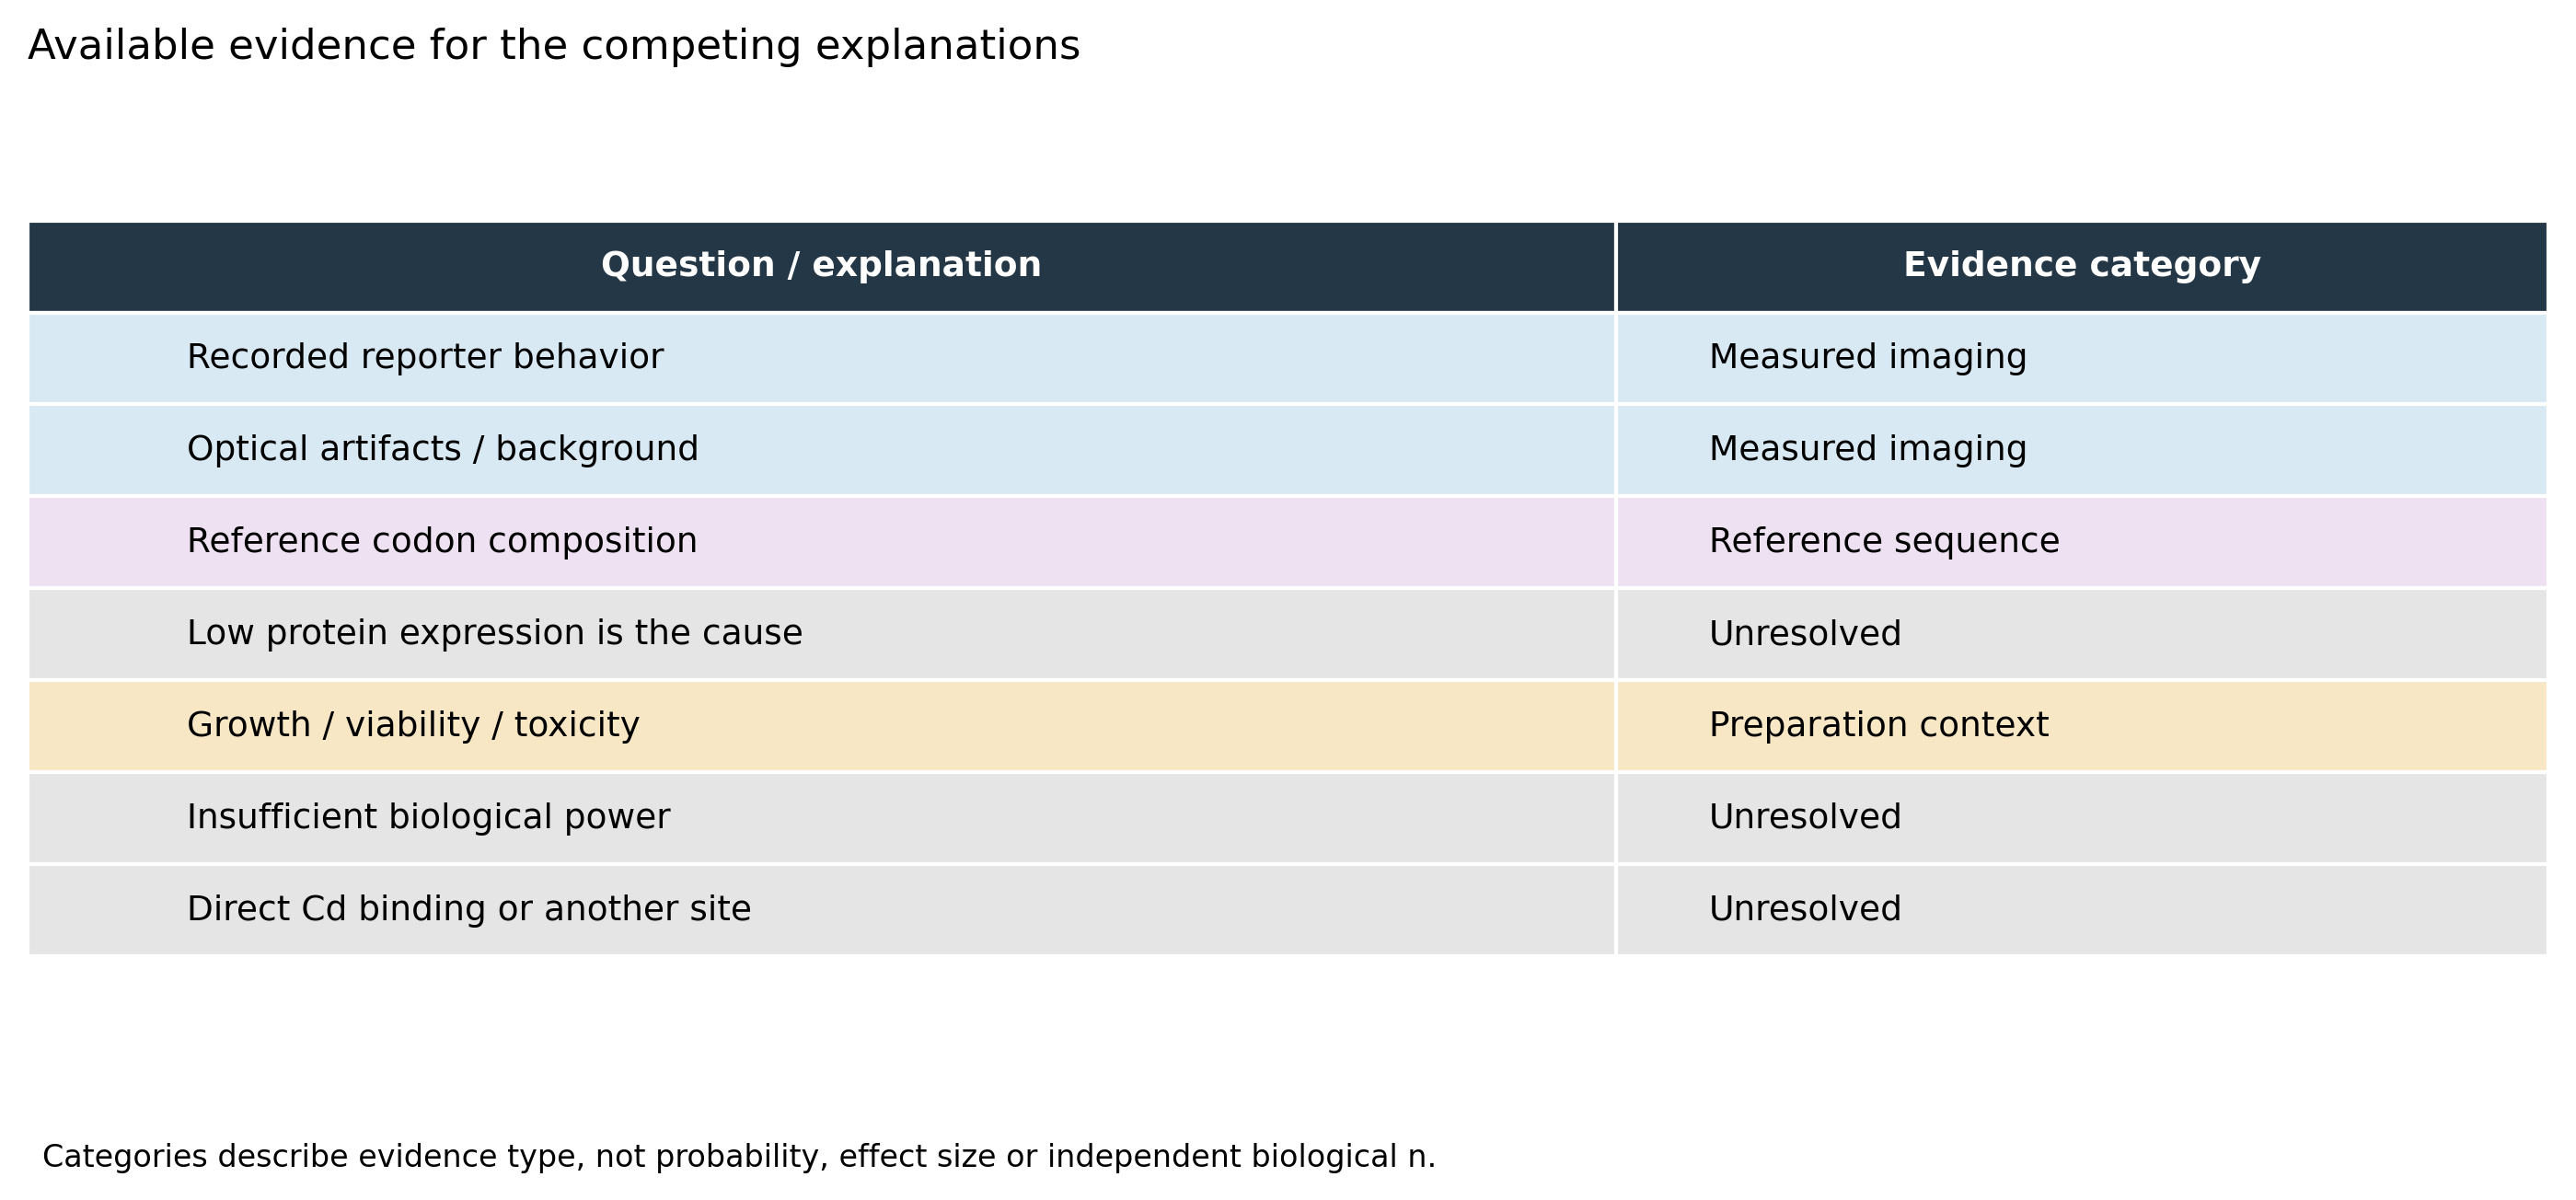

,Question / explanation,Evidence category,Input data,Finished without more wet-lab data?
0,Recorded reporter behavior,Measured imaging,F01_expanded_summary.json,Yes: evidence review; no: causal diagnosis
1,Optical artifacts / background,Measured imaging,F01_expanded_summary.json,Yes: evidence review; no: causal diagnosis
2,Reference codon composition,Reference sequence,CEX_C06_summary.json,Yes: evidence review; no: causal diagnosis
3,Low protein expression is the cause,Unresolved,No direct expression data,Yes: evidence review; no: causal diagnosis
4,Growth / viability / toxicity,Preparation context,F01_context_review.json,Yes: evidence review; no: causal diagnosis
5,Insufficient biological power,Unresolved,F01_expanded_summary.json,Yes: evidence review; no: causal diagnosis
6,Direct Cd binding or another site,Unresolved,No binding data,Yes: evidence review; no: causal diagnosis


### Source findings — retained verbatim

,Evidence ID,Source task,Finding
0,F-01-01,F-01,"120 input files, including derived context, were inventoried and byte-verified; 107 native/export image containers were processed."
1,F-01-02,F-01,20 time-series acquisitions; 14 with native clocks. All 146 static/Z frames are retained; 141 contain fluorescence and 94 have a usable BF-region metric.
2,F-01-03,F-01,"13 October, nominal 10 mM Ca / 5 mM Cd: C8: +2.66 ADU over 298.2s; Empty: +0.12 ADU over 299.5s; C6: +15.01 ADU over 298.4s; C1: +0.57 ADU over 299.6s; C2: +0.77 ADU over 299.6s. The C6 recording has the largest within-recording increase in this group. Candidate field-matched pre/post contrasts are C1 -10.22 ADU; C2 +1.92 ADU; Empty +0.68 ADU. Within-recording change and the field-matched treatment contrast answer different questions: the C1 field decreases across its paired acquisitions despite rising slightly within the challenged recording."
3,F-01-04,F-01,"No recording met the preset resolved-plateau criterion; an empirical reaction time constant, t50 and t90 were not estimated."
4,F-01-05,F-01,Four same-well comparisons meet the stage/BF field-match criterion. Their pre/post contrasts are tabulated separately from within-recording change.
5,F-01-06,F-01,Recorded stage Z spans 2.34 µm in C2 Ca 1 mM / Cd 5 mM and 1.08 µm in C2 Ca 10 mM / Cd 5 mM. PFS Status is code 1 except for three code-5 frames across those two C2 recordings; PFS offsets are constant within all 14 native time series. Codes are retained without assigning a lock-state meaning; stage motion alone does not establish defocus.
6,F-01-07,F-01,6 AVI files were decoded as processed-export QC and were not counted as additional biological observations.
7,C-06-01,C-06,The labelled CDS spans reference bases 748-2097: 1350 nt and 450 aa; its translation matches its annotation.
8,C-06-02,C-06,The adjacent triplet is TAA; a start-to-adjacent-stop segment has 1353 nt.
9,C-06-03,C-06,"Count-derived yeast-reference CAI is 0.1708, versus 0.1495 in the first 50 codons; zero = 1 gives 0.1764."


### Interpretation and next measurement for each explanation

,Question / explanation,Interpretation / next measurement
0,Recorded reporter behavior,Use the acquisition-specific findings; do not infer a universal response.
1,Optical artifacts / background,"Consult the native-depth, background, clipping, focus and movement checks for each recording."
2,Reference codon composition,Codon descriptors locate reference features; they are not measured protein expression.
3,Low protein expression is the cause,"Measure reporter abundance in the same confirmed clones, conditions and cultures."
4,Growth / viability / toxicity,Obtain same-sample growth and viability data to test this explanation.
5,Insufficient biological power,Identify independent cultures and obtain culture-level response variation.
6,Direct Cd binding or another site,Use a confirmed protein sequence/model and an explicitly defined binding question.


In [4]:
# Results: evidence coverage, exact upstream results and the complete review table.
display(Markdown('## Results'))
display(Image(filename=str(OUTPUT / 'evidence_matrix.png')))
display(matrix[['Question / explanation', 'Evidence category', 'Input data', 'Finished without more wet-lab data?']])
display(Markdown('### Source findings — retained verbatim'))
display(findings)
display(Markdown('### Interpretation and next measurement for each explanation'))
display(matrix[['Question / explanation', 'Interpretation / next measurement']])

## Interpretation

The new image analysis supplies quantitative evidence about the recorded reporter signal and technical behavior. The reference analysis supplies codon-composition evidence. The preparation notes document the experimental context. Together they make the alternatives explicit, but do not identify low protein expression as the cause of a weak response.

The next discriminating measurements are matched reporter-protein abundance in confirmed tested clones, independent-culture identities and same-sample growth/viability data. A possible additional cadmium-binding site remains a separate structural/biophysical question. The evidence review is complete; causal diagnosis remains open.